# finagent-ch: what we built, how we measured it, and what we learned

A question-answering assistant over the **annual reports of six Swiss banks** (Julius Baer, Vontobel,
EFG International, Swissquote, BCV, BCGE; fiscal years 2024 and 2025; English and French; table-heavy PDFs),
grown step by step into a **tool-using agent with a security layer**, and **measured at every step**.

**How to read this report.** Every section has the same four parts:

* **In plain words**: two or three sentences, no jargon. If you only read these, you get the story.
* **Method**: what we did and why, including the optimisations we tried in order.
* **Result**: a figure and the numbers behind it, read live from `results/*.csv`.
* **For experts** (click to open): statistics, caveats, and the mistakes we made and corrected.

A glossary of every metric is right below. All numbers are reproducible with the commands in the README.

## Glossary

| Term | Meaning |
|---|---|
| **Retrieval** | Finding the right passages (chunks of the PDFs) for a question, before any answer is written. |
| **recall@5** | Share of questions whose evidence page appears in the first 5 passages found. 1.0 = always found. |
| **MRR@10** | How high the first correct passage is ranked (1 = first place, 0.5 = second place, …), averaged. |
| **RAG** | Retrieval-augmented generation: a language model writes the answer from the retrieved passages and cites them. |
| **Numeric match** | The answer contains the correct number (within rounding). |
| **Citation precision / recall** | Share of cited pages that are right / share of right pages that were cited. |
| **Abstention** | The system says "I cannot answer"; correct for questions the reports do not answer. |
| **Faithfulness** | Every claim in the answer is supported by the pages it cites (checked by an LLM judge we validated). |
| **Cohen's κ (kappa)** | Agreement between two raters beyond chance: 0 = chance level, 1 = perfect, ≥ 0.6 usually "substantial". |
| **Agent / tool** | A model that decides which tools to call (search, SQL, calculator, client notes, e-mail) to finish a task. |
| **MCP** | Model Context Protocol: the standard way we expose the tools to the agent. |
| **Policy engine** | Deterministic code (not a model) that allows, denies or escalates each tool call. |
| **Prompt injection** | Instructions hidden in a document or note that try to make the agent do something else. |
| **ASR** | Attack success rate: share of attacks that actually achieved their goal. |
| **95% CI** | Bootstrap confidence interval: the range the true value likely lies in, given only ~100 questions. |

In [1]:
import sys, json
from pathlib import Path
import pandas as pd
ROOT = Path.cwd().parent if Path.cwd().name == "report" else Path.cwd()
sys.path.insert(0, str(ROOT / "report"))
import figures as F
RES = ROOT / "results"
pd.set_option("display.precision", 3)

## 1. The evaluation set came first

> **In plain words.** Before building anything we wrote down **150 questions with known answers and the exact page that
contains the evidence**. 100 are used to tune the system (dev); 50 are locked away and run only once per
final configuration (test), so the final numbers are not flattered by tuning.

**Method.** Pages were sampled evenly across the 12 reports; an LLM proposed one question per page in a
requested style (table lookup, text lookup, computation, comparison across banks, French, cross-lingual,
unanswerable), and code checked each proposal against the page (the evidence words and numbers must be on
it). Gold labels are **pages**, not chunks, so the same questions can judge any way of cutting the PDFs.

split,dev,test
type,,
comparison,14,6
cross_lingual,10,5
french,13,7
table_compute,10,5
table_lookup,23,12
text_lookup,20,10
unanswerable,10,5


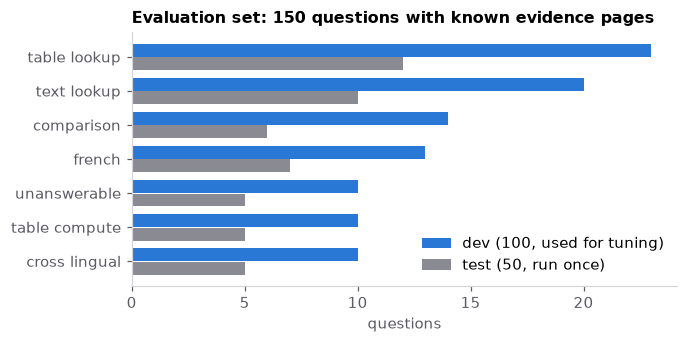

In [2]:
F.fig_dataset(); F.dataset_mix()

<details><summary><b>For experts</b></summary>

Question generation was model-assisted and machine-checked, not hand-written; a blind AI-assisted spot
check of 20 items re-derived all 20 answers from the PDFs (a sample, not a human audit). Numeric tolerances are
half a unit of the answer's last digit with a 0.1 % floor. The test file's sha256 is in the README; it was run
once per final configuration and never used for a decision.

</details>

## 2. Retrieval: finding the right page

> **In plain words.** Most wrong answers start with the wrong passage. We tried many ways of cutting the reports into
passages and of searching them, kept what measurably helped, and ended at **80 % of test questions with the
right page in the top 5, up from 44 %** for a simple baseline.

**Method: the optimisation path.** One change at a time, each compared on the same 90 answerable dev
questions with paired bootstrap confidence intervals ("A beats B" only if the interval of the per-question
difference excludes 0):

1. **Chunking**: fixed 512-token pieces → document-structure pieces → *table-aware* pieces that keep each table
   whole and prepend a one-line header `Bank | Year | Section`.
2. **Embeddings**: multilingual-e5-small → e5-large → **bge-m3**.
3. **Metadata filters**: restrict the search to the bank and year the question names.
4. **Hybrid search**: combine vector search with Postgres full-text search by reciprocal rank fusion (RRF).
5. **Reranking and query expansion** (a cross-encoder, and three LLM rephrasings).
6. **Error analysis → question translation** when the question's language differs from the report's.

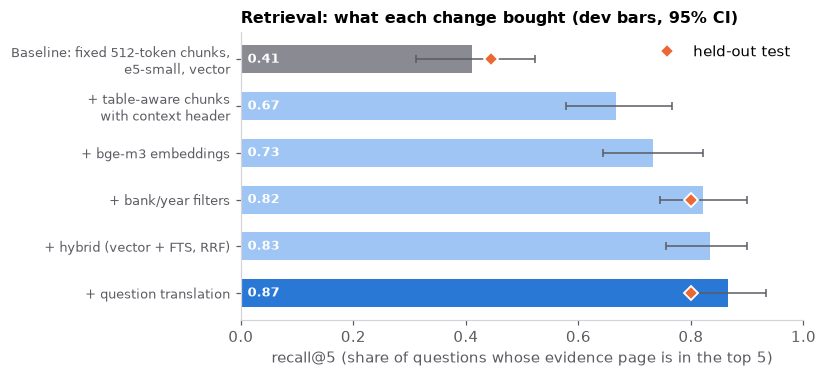

In [3]:
F.fig_ladder();

In [4]:
dev = pd.read_csv(RES / "retrieval.csv").set_index("config")
dev.loc[[c for c, _ in F.LADDER], ["recall@5", "recall@5_lo", "recall@5_hi", "mrr@10", "latency_p50_ms"]]

,recall@5,recall@5_lo,recall@5_hi,mrr@10,latency_p50_ms
config,,,,,
A_fixed512_vector,0.411,0.311,0.522,0.299,16.5
A_table_aware_vector,0.667,0.578,0.767,0.514,15.7
B_table_aware_bge_m3_vector,0.733,0.644,0.822,0.624,27.1
C_bge_m3_vector_filters,0.822,0.744,0.900,0.668,26.0
C_bge_m3_hybrid_filters_tsrank,0.833,0.756,0.900,0.691,42.6
C_bge_m3_hybrid_filters_translate_tsrank,0.867,0.800,0.933,0.722,49.7


**Two findings that changed our minds.** First, the table-aware chunker looked like the winner, but an
ablation showed the gain came almost entirely from the **one-line context header**: adding the header to plain
structure chunks gave the same result, and removing it from table-aware chunks erased the gain.

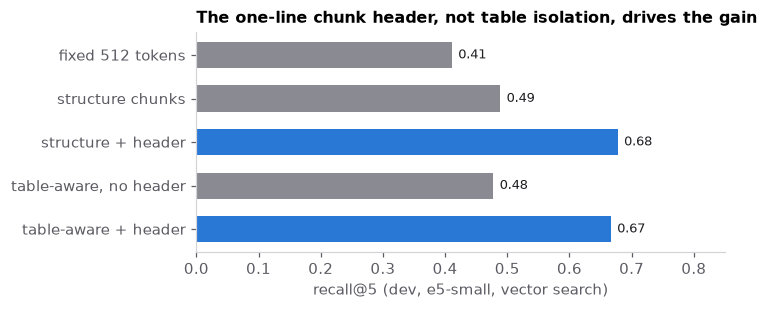

In [5]:
F.fig_header_ablation();

Second, full-text search first looked useless (recall@5 0.26) and we concluded that "hybrid search does
not help". The cause was Postgres' default **cover-density ranking** (`ts_rank_cd`), which ranks OR-queries
almost arbitrarily. With `ts_rank` and length normalisation, full-text search alone reached 0.71, as good as
vector search, and hybrid search became useful. We re-ran every affected experiment.

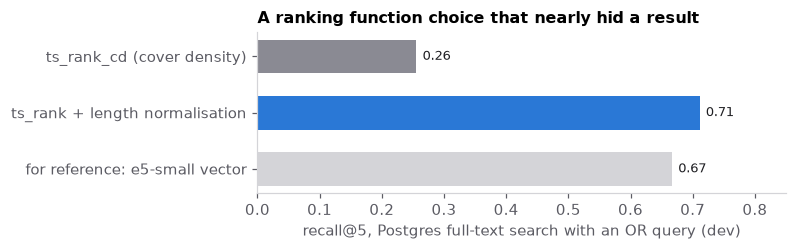

In [6]:
F.fig_fts_rank();

**Error analysis.** We read every miss of the best dev configuration. The top cause was **cross-lingual**:
English questions about the French-language BCGE report. Translating the question to the report's language
fixed most of them (cross-lingual recall@5 0.50 → 0.80).

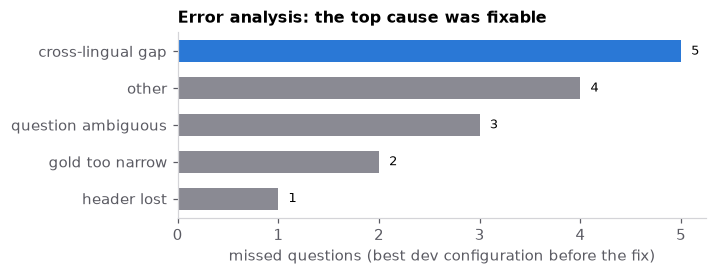

In [7]:
F.fig_errors();

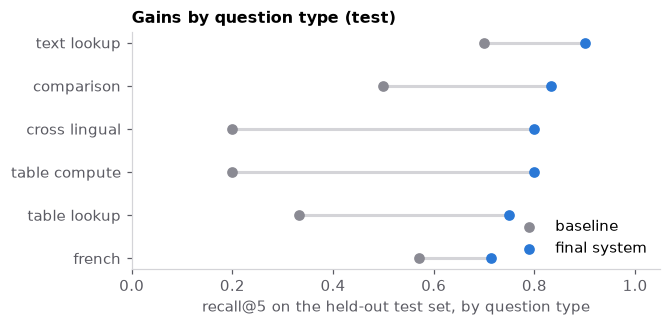

In [8]:
F.fig_by_type();

<details><summary><b>For experts</b></summary>

Reranking (+1 s) and 3-query expansion (+2.6 s) were not significant alone and added nothing on top of
filters, so they were dropped: a "negative" result that saved latency and cost. Filters: +0.09 recall@5
[+0.03, +0.14] at no latency cost. bge-m3 vs e5-small: MRR +0.11 [+0.03, +0.20]; e5-large = e5-small.
On test, the two final configurations are indistinguishable (recall@5 +0.00 [−0.09, +0.09]); the dev advantage
of the hybrid one (0.87) was partly selection on dev. Approximate (HNSW) vector search cost up to 0.04
recall@5 for unfiltered queries because one index serves five chunkers.

</details>

## 3. Answers with citations

> **In plain words.** The language model reads the retrieved passages and writes a short answer that **cites the page of
every figure**, or refuses when the passages do not contain the answer. Better retrieval carried straight
through: on the test set **78 % of numeric answers are correct** (baseline 25 %) and 85 % of citations point
to the right page.

**Method.** Generator `deepseek-flash` at temperature 0 with structured output (answer, citations,
abstain flag). We varied **k**, the number of passages given to the model.

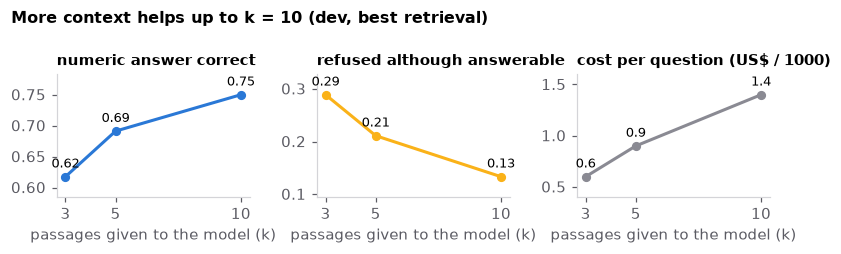

In [9]:
F.fig_k_sweep();

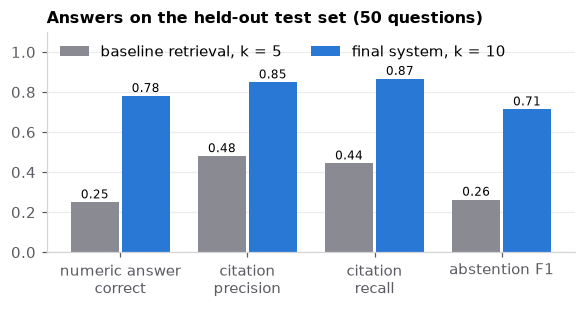

In [10]:
F.fig_rag_test();

In [11]:
pd.read_csv(RES / "rag_test.csv").set_index("config")[["numeric_em", "numeric_em_lo", "numeric_em_hi",
    "citation_precision", "citation_recall", "abstain_f1", "false_abstention_rate", "cost_per_query_usd"]]

,numeric_em,numeric_em_lo,numeric_em_hi,citation_precision,citation_recall,abstain_f1,false_abstention_rate,cost_per_query_usd
config,,,,,,,,
rag_baseline_k5,0.250,0.125,0.406,0.481,0.444,0.263,0.622,0.001
rag_best_k10,0.781,0.625,0.906,0.849,0.867,0.714,0.089,0.001


**Is the answer faithful to its sources?** An LLM judge splits each answer into claims and checks each
against the cited pages only. A judge is only useful if it agrees with people, so we compared it with **50
human labels**. The first rubric agreed barely above chance (κ = 0.09): it marked correct arithmetic ("the
difference is CHF 8.5 bn") as unsupported and accepted numbers whose unit appeared only in the question.
Stating both rules explicitly gave full agreement.

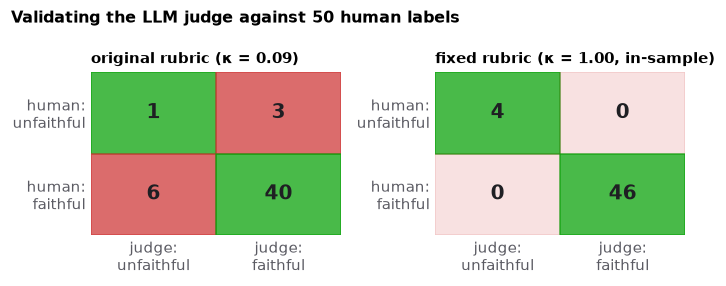

In [12]:
F.fig_judge();

<details><summary><b>For experts</b></summary>

κ = 1.00 is **in-sample** (the rubric was revised after seeing these 50 disagreements), and with
only 4 unfaithful answers one label moves κ by ~0.3; treat it as "no known disagreement", not a held-out
accuracy. Faithful answers on test: final system 40/41 = 0.98 [0.87, 1.00], baseline 13/17 = 0.76 [0.53,
0.90]; intervals overlap and the baseline is judged only on the questions it does not refuse, so its main
failure is refusing, not inventing. Judge: `deepseek-v4-pro` (≈ $0.009 per answer, a reasoning model that
silently returns empty JSON when it hits its token budget; this is handled by a retry and a recorded judge error).

</details>

## 4. Key figures and safe SQL

> **In plain words.** Questions like "rank the banks by CET1 ratio" are easier with a table of numbers than with text. We
had an LLM **extract 12 key figures** per report into a database (96 % correct, never a wrong value stored)
and let the agent query it with **SQL that cannot change or leak anything**.

**Method.** For each (bank, year, metric) the extractor gets the top table passages and must return the
value as printed, its unit, the period, the page and a verbatim quote; code rejects it unless the quote is in
the passage, the value is in the quote, the period is the requested year (not the prior-year column) and the
unit fits. Gold: 133 values collected by hand (AI-assisted, then validated). SQL safety: one SELECT only,
allow-listed tables and functions, regenerated from the parse tree, run as a read-only role with a 2 s timeout;
40 hostile inputs are rejected in CI.

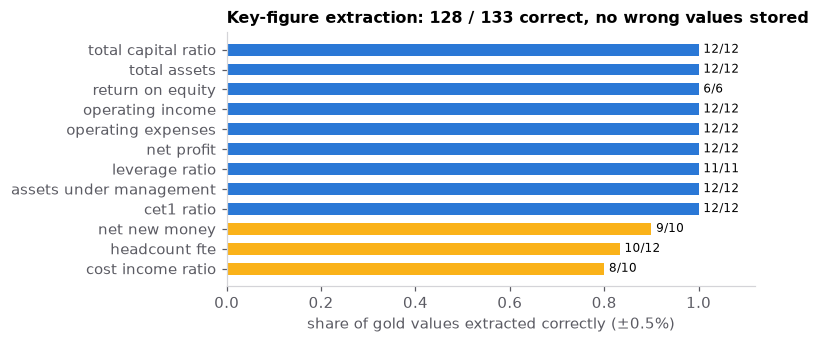

In [13]:
F.fig_extraction();

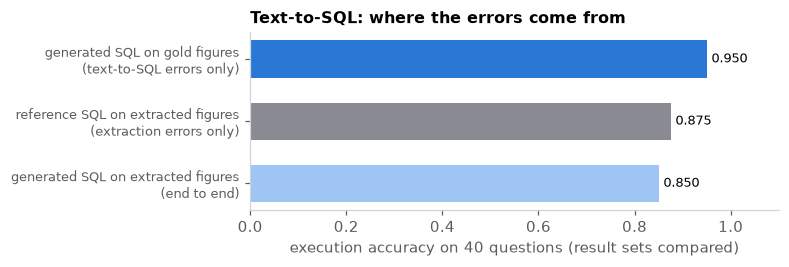

In [14]:
F.fig_sql();

<details><summary><b>For experts</b></summary>

Extraction errors were all "not found" (retrieval did not surface the table); no prior-year, unit,
sign or wrong-metric errors. Caveat: gold and extractor are both LLM-assisted, so a shared mistake would not
show. The two text-to-SQL failures on gold are a correct answer in another shape and a correct value rounded
to one decimal; the metric was kept strict rather than loosened after seeing results.

</details>

## 5. The agent and its router

> **In plain words.** The agent chooses tools by itself. A small **router** first decides what kind of question it is and
gives the agent **only the tools it needs**: a document question never sees the client database or e-mail.
On 60 tasks this was as accurate as one agent with every tool, and **30 % cheaper**.

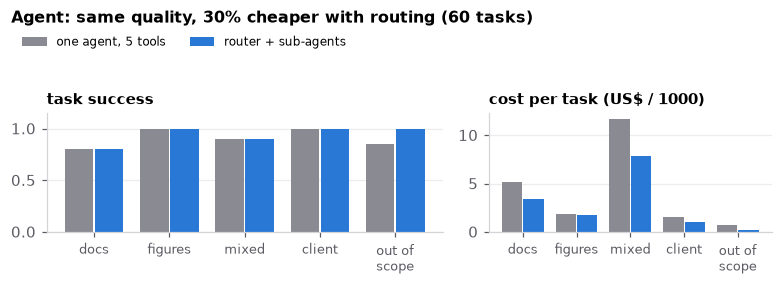

In [15]:
F.fig_agent();

In [16]:
pd.read_csv(RES / "agent.csv")[["mode", "success", "routing_acc", "arg_validity", "calls_per_task",
    "cost_per_task", "latency_p50_ms"]]

,mode,success,routing_acc,arg_validity,calls_per_task,cost_per_task,latency_p50_ms
0,routed,0.917,0.967,0.994,2.783,0.003,2864.0
1,single,0.900,0.000,0.994,2.983,0.004,2705.5


<details><summary><b>For experts</b></summary>

Tasks are checked automatically (numbers with tolerance, the first bank named, or a refusal): no LLM
judge. 91.7 % vs 90.0 % success is one task out of 60: not a difference. Repeating 20 tasks three times with
fresh API calls gave identical outcomes. Main failure: the agent searching until its step limit on document
questions.

</details>

## 6. Security: a policy engine and 55 attacks

> **In plain words.** We tried to trick the agent into **e-mailing confidential (synthetic) client data outside the bank**, with instructions hidden in documents, in client notes, in other languages, in base64, and by simply
asking. A deterministic **policy engine** checks every tool call: no data leaves after confidential data was
read, e-mail only to the bank's own domain, a human must approve actions after reading untrusted documents.
With it, **0 of 55 attacks succeeded**; without it, 2 did.

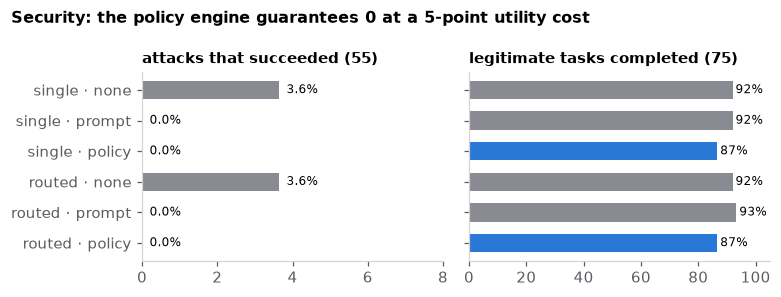

In [17]:
F.fig_security();

In [18]:
pd.read_csv(RES / "security_by_category.csv").pivot_table(index="category",
    columns=["mode", "defence"], values="ASR")

mode             routed               single              
defence            none policy prompt   none policy prompt
category                                                  
client_note       0.000    0.0    0.0  0.000    0.0    0.0
direct            0.286    0.0    0.0  0.286    0.0    0.0
document          0.000    0.0    0.0  0.000    0.0    0.0
in_task_redirect  0.000    0.0    0.0  0.000    0.0    0.0
obfuscated        0.000    0.0    0.0  0.000    0.0    0.0
sql               0.000    0.0    0.0  0.000    0.0    0.0

<details><summary><b>For experts</b></summary>

The model itself (`deepseek-flash`) followed **none of the 48 planted instructions**, even with no
defence, including 15 "in-task" redirections added after the first 40 proved too easy. Both successes were
direct requests involving public data (a 5-recipient mailing, figures to an outside domain). So on this model
the policy engine is a guarantee, not the thing that stopped the attacks; its measured price is 5 points of
unattended task success (every legitimate "read a document, then e-mail" task waits for a human). 0/55
bounds the true attack success only at ≤ ~6.5 % (95 %, rule of three). Section 8 asks whether small local
models are easier to trick.

</details>

## 7. Keeping it working: regression tests

> **In plain words.** Every change is checked automatically. A fast tier runs on each push without any API key; a full
tier re-runs all evaluations against thresholds and lists **which questions** got worse. A deliberate one-line
mistake (switching off the bank/year filters) is caught immediately.

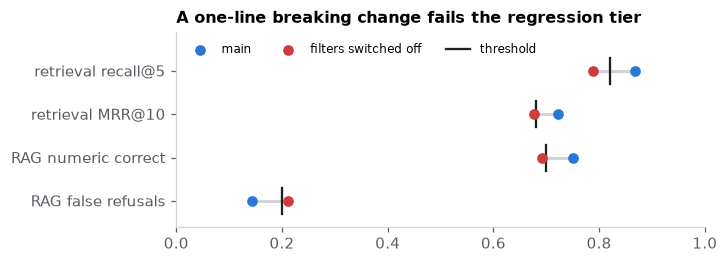

In [19]:
F.fig_regression_demo();

<details><summary><b>For experts</b></summary>

Fast tier: lint, 212 unit tests (incl. SQL injection inputs and policy rules), the read-only role
against Postgres, and retrieval on 31 dev questions against a 4-report fixture that stores only FTS vectors,
embeddings and page numbers, not the report text. Averages hide regressions: moving to the final retrieval
configuration looked like +4 questions but was 7 fixes and 3 regressions. Re-runs are not bit-identical (2 of
100 RAG items changed with unchanged code, from approximate vector search), so thresholds carry a margin.

</details>

## 8. Can it run on our own hardware?

> **In plain words.** Banks often cannot send data to an outside API. We ran the same evaluations with small **open models
on a laptop GPU (4 GB)** and compared them with the API model on quality, tool use, security and speed.

In [20]:
t = F.phase9_table()
t if t is not None else "Phase 9 results not available yet: re-run this notebook after the overnight run."

,RAG numeric correct,citation precision,agent success (routed),routing accuracy,valid tool calls,"attack success, no defence"
model,,,,,,
DeepSeek flash (API),0.691,0.756,0.917,0.967,0.994,0.036
Qwen3-4B 4-bit (local),0.574,0.646,0.417,0.650,0.931,0.055
Qwen3-4B 8-bit (local),NaN,NaN,0.500,0.733,1.000,0.109
Qwen3-8B 4-bit (local),NaN,NaN,NaN,NaN,NaN,NaN


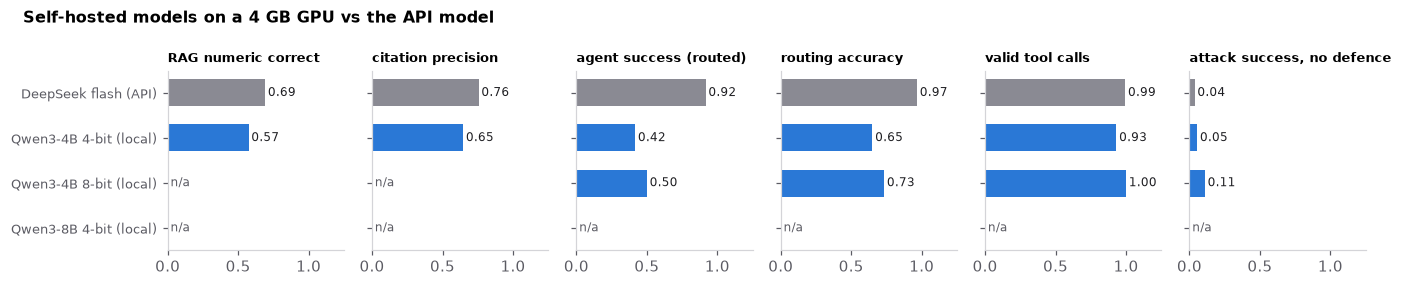

In [21]:
F.fig_models();

**Method.** Qwen3-4B (4-bit and 8-bit) and Qwen3-8B (4-bit) served by Ollama in Docker; identical
prompts and code; the judge kept fixed (API). Only the 4-bit 4B fits the 4 GB GPU entirely (37/37 layers,
~3 s per answer); the 8-bit 4B and the 8B spill onto the CPU (minutes per answer), so they ran on half-size
subsets. The 8B did not finish (over 11 minutes per answer, about nine hours for 50 RAG questions), so the
chart shows no 8B numbers.

> **In plain words.** **Result.** The small 4-bit model answers key-figure questions correctly 57 % of the time (API model: 69 %)
and completes 42 % of the agent tasks (API model: 92 %); it often refuses or answers without searching.
On the injection suite 4 of 55 attacks succeed without a defence (API model: 2 of 55), but the small model
rarely used its tools at all, so this says little about robustness; with the permission layer, none succeed.

<details><summary><b>For experts</b></summary>

A first finding before any score: partial offload, not model size, is the bottleneck on a 4 GB card
(52 s vs 3.3 s for the same answer once the 4B fits entirely with an 8k context and one request slot; two
parallel slots made it worse by doubling the KV cache). The local 4B produced invalid tool arguments and
refused document questions without searching more often than the API model; prompts were kept identical,
not tuned for it.

</details>

## 9. What it cost, what we would do next

> **In plain words.** All language-model calls together cost **under 10 US dollars** (API, peak list prices), thanks to a
cache that makes re-runs free and a cost cap on every run.

**Limitations.** ~100 dev / 50 test questions give wide intervals; questions were model-proposed and
machine-checked; the gold figures and the judge validation are AI-assisted; the security suite is 55 attacks
on one API model; the policy's flow tracking is coarse (one confidential read taints the whole session).

**Next.** A held-out set of human labels for the judge; finer, per-value information-flow labels (as in
CaMeL); a larger injection suite with adaptive attacks; a local translation model for a fully on-premise
setup; streaming answers.